# Login, GPU check

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
print(torch.cuda.device_count())

import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF2")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("Hugging Face login successful.")

import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

1


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.
CUDA available: True
GPU count: 1
GPU 0: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [2]:
import os, random, json, time, math, zipfile, shutil
import numpy as np
import torch

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_TEXT_FILES = ["Phase_2_LNER/Train/fold1-text.json", "Phase_2_LNER/Train/fold2-text.json"]
TRAIN_GOLD_FILES = ["Phase_2_LNER/Train/fold1-gold.json", "Phase_2_LNER/Train/fold2-gold.json"]
LABELS_FILE = "Phase_2_LNER/Train/labels.txt"
TEST_TEXT_FILE = "Phase_2_LNER/Test/fold3-text.json"

# ---------------- Student: Model 2 (RMSNorm + SwiGLU), Phase 1 checkpoint ----------------
STUDENT_CKPT_DIR = "/kaggle/input/datasets/himangshumahato/rmsnorm-swigelu-model2"

# ---------------- Teacher: Model 4 (Prefix-LM), your full-fine-tuned Phase 2 NER checkpoint ----------------
# This must be the OUTPUT_DIR you saved from the full-fine-tuning notebook, uploaded as a Kaggle Dataset.
TEACHER_CKPT_DIR = "/kaggle/input/datasets/himangshumahato/prefixlm-best-model" 
TEACHER_N_EMBD, TEACHER_N_LAYER, TEACHER_N_HEAD, TEACHER_N_KV_HEAD = 768, 12, 12, 4

MODEL_CONTEXT_LENGTH = 1024
N_EMBD = 768
N_LAYER = 12
N_HEAD = 12

WINDOW_SIZE = 1024
WINDOW_STRIDE = 512
HEADER_TOKENS = 64

# ---------------- Knowledge Distillation ----------------
KD_TEMPERATURE = 2.0
KD_ALPHA = 0.5     # weight on hard-label loss; (1-KD_ALPHA) on soft teacher-matching loss

# ---------------- Training ----------------
EPOCHS = 15
BATCH_SIZE = 2
GRAD_ACCUM = 8
LR_BACKBONE = 3e-5
LR_HEAD = 1e-3
WEIGHT_DECAY = 0.05
WARMUP_RATIO = 0.10
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

EXPERIMENT_NAME = "model2_kd_student"
OUTPUT_DIR = f"/kaggle/working/cs781_phase2/{EXPERIMENT_NAME}"
MODEL_PATH = os.path.join(OUTPUT_DIR, "best_model.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Configuration loaded:", EXPERIMENT_NAME)

Configuration loaded: model2_kd_student


In [3]:
!pip -q install regex
from huggingface_hub import hf_hub_download, HfApi

info = HfApi().dataset_info(HF_DATASET_REPO, files_metadata=True, token=HF_TOKEN)
for s in info.siblings:
    if "Phase_2" in s.rfilename:
        print(f"{s.rfilename:70s} {s.size/1e6:.2f} MB")

Phase_2_LNER/Test/fold3-text.json                                      1.19 MB
Phase_2_LNER/Train/fold1-gold.json                                     0.46 MB
Phase_2_LNER/Train/fold1-text.json                                     1.11 MB
Phase_2_LNER/Train/fold2-gold.json                                     0.48 MB
Phase_2_LNER/Train/fold2-text.json                                     1.12 MB
Phase_2_LNER/Train/labels.txt                                          0.00 MB


## 4. Load Tokenizer

In [4]:
%%writefile a1_tokenizer.py
"""From-scratch byte-level BPE tokenizer (GPT-2 style)."""
from __future__ import annotations
import heapq, json, time
from collections import Counter, defaultdict
import regex as re

_PAT = re.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")
EOS_TOKEN = "<|endoftext|>"

class ByteLevelBPE:
    def __init__(self):
        self.merges: dict[tuple[int, int], int] = {}
        self.itos: dict[int, bytes] = {i: bytes([i]) for i in range(256)}
        self.eos_token_id = 256
        self.vocab_size = 257
        self._cache: dict[str, tuple] = {}

    @property
    def pad_token_id(self): return self.eos_token_id
    @property
    def bos_token_id(self): return self.eos_token_id
    def __len__(self): return self.vocab_size
    def get_vocab_size(self): return self.vocab_size

    def _encode_word(self, word):
        if word in self._cache:
            return self._cache[word]
        ids = list(word.encode("utf-8"))
        while len(ids) > 1:
            pairs = {(ids[i], ids[i+1]) for i in range(len(ids)-1)}
            ranked = [(self.merges[p], p) for p in pairs if p in self.merges]
            if not ranked:
                break
            _, best = min(ranked)
            new_id = self.merges[best]
            out, i = [], 0
            while i < len(ids):
                if i < len(ids)-1 and (ids[i], ids[i+1]) == best:
                    out.append(new_id); i += 2
                else:
                    out.append(ids[i]); i += 1
            ids = out
        self._cache[word] = tuple(ids)
        return tuple(ids)

    def encode(self, text, add_eos=False):
        out = []
        for w in _PAT.findall(text):
            out.extend(self._encode_word(w))
        if add_eos:
            out.append(self.eos_token_id)
        return out

    def decode(self, ids, skip_special_tokens=True):
        parts = []
        for i in ids:
            if i == self.eos_token_id:
                if skip_special_tokens:
                    continue
                parts.append(EOS_TOKEN.encode())
            else:
                parts.append(self.itos[i])
        return b"".join(parts).decode("utf-8", errors="replace")

    def save(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": [[list(p), n] for p, n in self.merges.items()],
                       "vocab_size": self.vocab_size, "eos_token_id": self.eos_token_id}, f)

    @classmethod
    def load(cls, path):
        with open(path, encoding="utf-8") as f:
            d = json.load(f)
        t = cls()
        for a, b, n in d["merges"]:
            t.merges[(a, b)] = n
            t.itos[n] = t.itos[a] + t.itos[b]
        t.eos_token_id = d["eos_token_id"]
        t.vocab_size = d["vocab_size"]
        return t

Overwriting a1_tokenizer.py


In [5]:
from a1_tokenizer import ByteLevelBPE, _PAT
tokenizer = ByteLevelBPE.load(os.path.join(STUDENT_CKPT_DIR, "bpe_tokenizer.json"))
print("Vocabulary size:", len(tokenizer))

Vocabulary size: 32000


In [6]:
def encode_with_offsets(tok, text):
    ids, starts, ends, is_ws = [], [], [], []
    pos = 0
    for m in _PAT.finditer(text):
        assert m.start() == pos, "pre-tokenizer left a gap in the text"
        pos = m.end()
        word, c0 = m.group(), m.start()
        b2c = []
        for i, ch in enumerate(word):
            b2c.extend([c0 + i] * len(ch.encode("utf-8")))
        b = 0
        for tid in tok._encode_word(word):
            n = len(tok.itos[tid])
            s, e = b2c[b], b2c[b + n - 1] + 1
            b += n
            while s < e and text[s].isspace(): s += 1
            while e > s and text[e - 1].isspace(): e -= 1
            ids.append(tid); starts.append(s); ends.append(e); is_ws.append(s >= e)
    assert pos == len(text), "pre-tokenizer did not cover the whole text"
    return ids, starts, ends, is_ws

# Data loading

In [7]:
from huggingface_hub import hf_hub_download

def hf_json(path):
    p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=path, repo_type="dataset", token=HF_TOKEN)
    with open(p, encoding="utf-8") as f:
        return json.load(f)

train_text, train_gold, doc_fold = {}, {}, {}
for fold_i, (tf, gf) in enumerate(zip(TRAIN_TEXT_FILES, TRAIN_GOLD_FILES), start=1):
    t, g = hf_json(tf), hf_json(gf)
    train_text.update(t); train_gold.update(g)
    for d in t: doc_fold[d] = fold_i

test_text = hf_json(TEST_TEXT_FILE)
p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=LABELS_FILE, repo_type="dataset", token=HF_TOKEN)
LABELS = [l.strip() for l in open(p, encoding="utf-8") if l.strip()]
print("train docs:", len(train_text), "| gold docs:", len(train_gold), "| test docs:", len(test_text))

train docs: 70 | gold docs: 70 | test docs: 35


In [8]:
for d in list(train_text)[:5]:
    ids, s, e, w = encode_with_offsets(tokenizer, train_text[d])
    assert ids == tokenizer.encode(train_text[d]), d
print("ids match encode()")

ids match encode()


In [9]:
TAGS = ["O"] + [f"{p}-{l}" for l in LABELS for p in ("B", "I")]
TAG2ID = {t: i for i, t in enumerate(TAGS)}
ID2TAG = {i: t for t, i in TAG2ID.items()}
IGNORE = -100
print(len(TAGS), "tags:", TAGS[:5], "...")

25 tags: ['O', 'B-APP', 'I-APP', 'B-RESP', 'I-RESP'] ...


In [10]:
def spans_to_bio(starts, ends, is_ws, gold_spans):
    ents = sorted(gold_spans, key=lambda x: (x[0], x[1]))
    tags, k, prev_ent = [], 0, -1
    for i in range(len(starts)):
        if is_ws[i]:
            tags.append(IGNORE); continue
        while k < len(ents) and ents[k][1] <= starts[i]:
            k += 1
        if k < len(ents) and ents[k][0] <= starts[i] < ents[k][1]:
            prefix = "I-" if prev_ent == k else "B-"
            tags.append(TAG2ID[prefix + ents[k][2]]); prev_ent = k
        else:
            tags.append(TAG2ID["O"]); prev_ent = -1
    return tags

def bio_to_spans(starts, ends, is_ws, tag_ids):
    spans, cur = [], None
    for i, t in enumerate(tag_ids):
        if is_ws[i] or t == IGNORE: continue
        tag = ID2TAG[int(t)]
        if tag == "O":
            if cur: spans.append(cur); cur = None
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "I" and cur is not None and cur[2] == label:
            cur[1] = ends[i]
        else:
            if cur: spans.append(cur)
            cur = [starts[i], ends[i], label]
    if cur: spans.append(cur)
    return spans

def span_set(spans):
    return {tuple(x[:3]) for x in spans}

## Encode every document once (train and test)

In [11]:
enc = {}
for d, t in {**train_text, **test_text}.items():
    enc[d] = encode_with_offsets(tokenizer, t)
tags_by_doc = {d: spans_to_bio(*enc[d][1:], train_gold[d]) for d in train_gold}
print("encoded docs:", len(enc), "| tagged docs:", len(tags_by_doc))

encoded docs: 105 | tagged docs: 70


## Windows

In [12]:
def window_starts(n_tokens, size, stride):
    if n_tokens <= size:
        return [0]
    starts = list(range(0, n_tokens - size + 1, stride))
    if starts[-1] + size < n_tokens:
        starts.append(n_tokens - size)
    return starts

def build_windows(doc_ids, size=WINDOW_SIZE, stride=WINDOW_STRIDE, with_labels=True, header_tokens=HEADER_TOKENS):
    items = []
    body_size = size - header_tokens
    for d in doc_ids:
        ids = enc[d][0]
        tags = tags_by_doc.get(d) if with_labels else None
        n = len(ids)
        header_ids = ids[:header_tokens]
        for ws in window_starts(n, body_size, stride):
            if ws == 0:
                input_ids = ids[0:size]; body_start = 0
            else:
                input_ids = header_ids + ids[ws:ws + body_size]; body_start = header_tokens
            body_len = len(input_ids) - body_start
            item = {"doc": d, "doc_start": ws, "body_start": body_start, "input_ids": input_ids}
            if with_labels:
                item["labels"] = [IGNORE] * body_start + tags[ws:ws + body_len]
            items.append(item)
    return items

fold1_docs = [d for d, f in doc_fold.items() if f == 1]
fold2_docs = [d for d, f in doc_fold.items() if f == 2]
all_docs = fold1_docs + fold2_docs
random.Random(SEED).shuffle(all_docs)
n_val = max(1, int(0.1 * len(all_docs)))
val_docs, train_docs = all_docs[:n_val], all_docs[n_val:]

train_items = build_windows(train_docs)
val_items   = build_windows(val_docs)
print(f"train docs: {len(train_docs)} | val docs: {len(val_docs)} | train windows: {len(train_items)} | val windows: {len(val_items)}")

for d in train_docs[:5]:
    covered = set()
    for it in train_items:
        if it["doc"] == d:
            body_len = len(it["input_ids"]) - it["body_start"]
            covered.update(range(it["doc_start"], it["doc_start"] + body_len))
    assert covered == set(range(len(enc[d][0]))), d
print("window coverage OK")

train docs: 63 | val docs: 7 | train windows: 807 | val windows: 73
window coverage OK


## Collator

In [13]:
PAD_ID = tokenizer.eos_token_id

def ner_collator(batch):
    L = WINDOW_SIZE
    ids = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    lab = torch.full((len(batch), L), IGNORE, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.bool)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"])
        mask[i, :n] = True
        if "labels" in b:
            lab[i, :n] = torch.tensor(b["labels"])
    return {"input_ids": ids, "attention_mask": mask, "labels": lab}

## 9. Define The Model

## Building Model 2: RMSNorm + SwiGLU Variant
Instead of changing the overall macro-architecture (making it an encoder-decoder like T5, or an encoder-only like BERT), Model 2 upgrades internal micro-architectural components to match modern state-of-the-art decoder-only models (like LLaMA or Mistral):

RMSNorm (Root Mean Square Layer Normalization): Simpler and more computationally efficient than standard LayerNorm by omitting the mean-centering step.

SwiGLU Activation Function: A gated linear unit variant using the SiLU (Swish) activation, which is widely adopted in state-of-the-art open-source LLMs.

In [14]:
import math
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        variance = x.pow(2).mean(-1, keepdim=True)
        return x * torch.rsqrt(variance + self.eps) * self.weight


class SwiGLUMLP(nn.Module):
    def __init__(self, n_embd, dropout=0.1, hidden_mult=4):
        super().__init__()
        hidden = int(n_embd * hidden_mult * 2 / 3)   # standard SwiGLU sizing, keeps param count comparable to 4x-GELU MLP
        self.gate_proj = nn.Linear(n_embd, hidden)
        self.up_proj = nn.Linear(n_embd, hidden)
        self.down_proj = nn.Linear(hidden, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x)))


class CausalSelfAttentionRMS(nn.Module):
    def __init__(self, n_embd, n_head, n_positions, dropout=0.1):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.n_embd = n_embd
        self.head_dim = n_embd // n_head
        self.c_attn = nn.Linear(n_embd, 3 * n_embd)
        self.c_proj = nn.Linear(n_embd, n_embd)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer("bias", torch.tril(torch.ones(n_positions, n_positions)).view(1, 1, n_positions, n_positions))

    def forward(self, x, layer_past=None, attn_mask=None):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        if layer_past is not None:
            past_k, past_v = layer_past
            k = torch.cat([past_k, k], dim=-2)
            v = torch.cat([past_v, v], dim=-2)
        present = (k, v)
        past_length = layer_past[0].size(-2) if layer_past is not None else 0
        seq_len = T + past_length

        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(self.head_dim))
        if attn_mask is not None:
            att = att.masked_fill(~attn_mask, float('-inf'))
        else:
            mask = self.bias[:, :, past_length:past_length + T, :seq_len] == 0
            att = att.masked_fill(mask, float('-inf'))

        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.c_proj(y)), present


class RMSSwiGLUBlock(nn.Module):
    def __init__(self, n_embd, n_head, n_positions, dropout=0.1):
        super().__init__()
        self.ln_1 = RMSNorm(n_embd)
        self.attn = CausalSelfAttentionRMS(n_embd, n_head, n_positions, dropout)
        self.ln_2 = RMSNorm(n_embd)
        self.mlp = SwiGLUMLP(n_embd, dropout)

    def forward(self, x, layer_past=None, attn_mask=None):
        a, present = self.attn(self.ln_1(x), layer_past=layer_past, attn_mask=attn_mask)
        x = x + a
        x = x + self.mlp(self.ln_2(x))
        return x, present


class RMSSwiGLULM(nn.Module):
    def __init__(self, vocab_size, n_positions, n_embd, n_layer, n_head, dropout=0.1):
        super().__init__()
        self.wte = nn.Embedding(vocab_size, n_embd)
        self.wpe = nn.Embedding(n_positions, n_embd)
        self.drop = nn.Dropout(dropout)
        self.h = nn.ModuleList([RMSSwiGLUBlock(n_embd, n_head, n_positions, dropout) for _ in range(n_layer)])
        self.ln_f = RMSNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)
        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("c_proj.weight") or name.endswith("down_proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None: nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

## The LoRMA technique

In [15]:
class GroupedQueryAttention(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        self.n_head = n_head; self.n_kv_head = n_kv_head
        self.head_dim = n_embd // n_head
        self.num_groups = n_head // n_kv_head
        self.q_proj = nn.Linear(n_embd, n_embd)
        self.k_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        self.v_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        self.c_proj = nn.Linear(n_embd, n_embd)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer("bias", torch.tril(torch.ones(n_positions, n_positions)).view(1, 1, n_positions, n_positions))

    def forward(self, x, layer_past=None, attn_mask=None):
        B, T, C = x.size()
        q = self.q_proj(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        if layer_past is not None:
            past_k, past_v = layer_past
            k = torch.cat([past_k, k], dim=-2); v = torch.cat([past_v, v], dim=-2)
        present = (k, v)
        past_length = layer_past[0].size(-2) if layer_past is not None else 0
        seq_len = T + past_length
        k = k.repeat_interleave(self.num_groups, dim=1)
        v = v.repeat_interleave(self.num_groups, dim=1)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(self.head_dim))
        if attn_mask is not None:
            att = att.masked_fill(~attn_mask, float('-inf'))
        else:
            mask = self.bias[:, :, past_length:past_length + T, :seq_len] == 0
            att = att.masked_fill(mask, float('-inf'))
        att = F.softmax(att, dim=-1); att = self.attn_dropout(att)
        y = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.c_proj(y)), present


class GQATransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd)
        self.attn = GroupedQueryAttention(n_embd, n_head, n_kv_head, n_positions, dropout)
        self.ln_2 = nn.LayerNorm(n_embd)
        self.mlp = nn.Sequential(nn.Linear(n_embd, 4*n_embd), nn.GELU(approximate='tanh'),
                                 nn.Linear(4*n_embd, n_embd), nn.Dropout(dropout))

    def forward(self, x, layer_past=None, attn_mask=None):
        a, present = self.attn(self.ln_1(x), layer_past=layer_past, attn_mask=attn_mask)
        x = x + a
        x = x + self.mlp(self.ln_2(x))
        return x, present


class PrefixLM(nn.Module):
    def __init__(self, vocab_size, n_positions, n_embd, n_layer, n_head, n_kv_head, dropout=0.1):
        super().__init__()
        self.wte = nn.Embedding(vocab_size, n_embd)
        self.wpe = nn.Embedding(n_positions, n_embd)
        self.drop = nn.Dropout(dropout)
        self.h = nn.ModuleList([GQATransformerBlock(n_embd, n_head, n_kv_head, n_positions, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

# The NEW model

In [16]:
class NERModel(nn.Module):
    """Wraps either backbone (student or teacher) with an identical NER head and bidirectional attention."""
    def __init__(self, lm, n_tags, n_embd, dropout=0.1):
        super().__init__()
        self.lm = lm
        if hasattr(self.lm, "lm_head"):
            del self.lm.lm_head
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(n_embd, n_embd), nn.GELU(approximate='tanh'),
            nn.Dropout(dropout), nn.Linear(n_embd, n_tags)
        )

    def forward(self, input_ids, labels=None, attention_mask=None, class_weights=None, return_logits_only=False):
        B, T = input_ids.shape
        positions = torch.arange(T, device=input_ids.device)
        x = self.lm.wte(input_ids) + self.lm.wpe(positions)
        x = self.lm.drop(x)

        attn_mask = torch.ones(B, 1, T, T, dtype=torch.bool, device=input_ids.device)
        if attention_mask is not None:
            key_visible = attention_mask[:, None, None, :].bool()
            attn_mask = attn_mask & key_visible

        for block in self.lm.h:
            x, _ = block(x, attn_mask=attn_mask)
        x = self.lm.ln_f(x)
        logits = self.head(self.dropout(x))

        if return_logits_only:
            return logits

        loss = None
        if labels is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), labels.view(-1),
                                   weight=class_weights, ignore_index=IGNORE)
        return {"loss": loss, "logits": logits}

## Distillation loss

In [17]:
def distillation_loss(student_logits, teacher_logits, labels, class_weights, T=KD_TEMPERATURE, alpha=KD_ALPHA):
    hard = F.cross_entropy(student_logits.view(-1, student_logits.size(-1)),
                           labels.view(-1), weight=class_weights, ignore_index=IGNORE)
    mask = (labels.view(-1) != IGNORE)
    s_flat = student_logits.view(-1, student_logits.size(-1))[mask]
    t_flat = teacher_logits.view(-1, teacher_logits.size(-1))[mask]
    soft = F.kl_div(F.log_softmax(s_flat / T, dim=-1), F.softmax(t_flat / T, dim=-1), reduction="batchmean") * (T ** 2)
    return alpha * hard + (1 - alpha) * soft

## Load the Phase 1 backbone

In [18]:
from torch.utils.data import DataLoader
from torch.optim import AdamW
from safetensors.torch import load_file

# 1. Teacher: Prefix-LM, loaded with its NER head + fine-tuned weights, fully frozen
teacher_lm = PrefixLM(vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
                       n_embd=TEACHER_N_EMBD, n_layer=TEACHER_N_LAYER, n_head=TEACHER_N_HEAD, n_kv_head=TEACHER_N_KV_HEAD)
teacher_model = NERModel(teacher_lm, n_tags=len(TAGS), n_embd=TEACHER_N_EMBD).to(device)
teacher_model.load_state_dict(torch.load(os.path.join(TEACHER_CKPT_DIR, "best_model.pt"), weights_only=True))
teacher_model.eval()
for p in teacher_model.parameters():
    p.requires_grad = False
print("Teacher loaded, frozen.")

# 2. Student: Model 2 backbone from Phase 1, fully trainable
student_lm = RMSSwiGLULM(vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
                          n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD)

raw_state = load_file(os.path.join(STUDENT_CKPT_DIR, "model.safetensors"))
mapped_state = {}

for k, v in raw_state.items():
    if ".mlp.w1.weight" in k:
        k = k.replace(".mlp.w1.weight", ".mlp.gate_proj.weight")
    elif ".mlp.w1.bias" in k:
        k = k.replace(".mlp.w1.bias", ".mlp.gate_proj.bias")
    elif ".mlp.w3.weight" in k:
        k = k.replace(".mlp.w3.weight", ".mlp.up_proj.weight")
    elif ".mlp.w3.bias" in k:
        k = k.replace(".mlp.w3.bias", ".mlp.up_proj.bias")
    elif ".mlp.w2.weight" in k:
        k = k.replace(".mlp.w2.weight", ".mlp.down_proj.weight")
    elif ".mlp.w2.bias" in k:
        k = k.replace(".mlp.w2.bias", ".mlp.down_proj.bias")
    mapped_state[k] = v

# Use strict=False to gracefully handle architectural bias differences between Phase 1 and current class definition
missing_keys, unexpected_keys = student_lm.load_state_dict(mapped_state, strict=False)
print("Student backbone loaded with strict=False!")
if missing_keys:
    print(f"  -> Ignored missing keys (e.g., biases): {len(missing_keys)} keys")
if unexpected_keys:
    print(f"  -> Ignored unexpected keys: {len(unexpected_keys)} keys")

ner_model = NERModel(student_lm, n_tags=len(TAGS), n_embd=N_EMBD).to(device)
for p in ner_model.parameters():
    p.requires_grad = True

backbone_params = [p for n, p in ner_model.named_parameters() if "head" not in n]
head_params = [p for n, p in ner_model.named_parameters() if "head" in n]
optimizer = AdamW([
    {"params": backbone_params, "lr": LR_BACKBONE},
    {"params": head_params, "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

trainable = sum(p.numel() for p in ner_model.parameters() if p.requires_grad)
print(f"Student trainable parameters: {trainable:,}")

train_loader = DataLoader(train_items, batch_size=BATCH_SIZE, shuffle=True, collate_fn=ner_collator)
val_loader   = DataLoader(val_items,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=ner_collator)

steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(WARMUP_RATIO * total_steps)

def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
print("Optimizer steps:", total_steps, "| warmup:", warmup_steps)

@torch.no_grad()
def eval_loss(model, loader):
    model.eval()
    tot, n = 0.0, 0
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        out = model(**b)
        k = (b["labels"] != IGNORE).sum().item()
        tot += out["loss"].item() * k; n += k
    return tot / n

Teacher loaded, frozen.
Student backbone loaded with strict=False!
  -> Ignored missing keys (e.g., biases): 36 keys
Student trainable parameters: 111,021,337
Optimizer steps: 765 | warmup: 76


## Prediction, Viterbi decoding, strict scorer

In [19]:
@torch.no_grad()
def predict_doc_logprobs(model, doc_id, size=WINDOW_SIZE, stride=WINDOW_STRIDE, bs=16, header_tokens=HEADER_TOKENS):
    model.eval()
    ids = enc[doc_id][0]
    n = len(ids)
    header_ids = ids[:header_tokens]
    body_size = size - header_tokens
    acc = torch.zeros(n, len(TAGS))
    cnt = torch.zeros(n)
    windows = []
    for ws in window_starts(n, body_size, stride):
        if ws == 0:
            windows.append({"input_ids": ids[0:size], "doc_start": ws, "body_start": 0})
        else:
            windows.append({"input_ids": header_ids + ids[ws:ws + body_size], "doc_start": ws, "body_start": header_tokens})
    for i in range(0, len(windows), bs):
        chunk = windows[i:i + bs]
        batch = ner_collator([{"input_ids": w["input_ids"]} for w in chunk])
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=batch["input_ids"].to(device))["logits"]
        lp = logits.float().log_softmax(-1).cpu()
        for j, w in enumerate(chunk):
            body_len = len(w["input_ids"]) - w["body_start"]
            doc_slice = lp[j, w["body_start"]:w["body_start"] + body_len]
            acc[w["doc_start"]:w["doc_start"] + body_len] += doc_slice
            cnt[w["doc_start"]:w["doc_start"] + body_len] += 1
    return acc / cnt[:, None]

K = len(TAGS)
trans_ok = np.zeros((K, K), dtype=bool)
for i, from_tag in enumerate(TAGS):
    for j, to_tag in enumerate(TAGS):
        if to_tag == "O":
            trans_ok[i, j] = True
        else:
            to_prefix, to_label = to_tag.split("-", 1)
            if to_prefix == "B":
                trans_ok[i, j] = True
            else:
                if from_tag == "O":
                    trans_ok[i, j] = False
                else:
                    from_prefix, from_label = from_tag.split("-", 1)
                    trans_ok[i, j] = (from_label == to_label)
NEG_INF = -1e9

def viterbi_decode(logprobs):
    T, K_ = logprobs.shape
    dp = np.full((T, K_), NEG_INF)
    bp = np.zeros((T, K_), dtype=np.int32)
    dp[0] = logprobs[0]
    for t in range(1, T):
        scores = np.where(trans_ok, dp[t - 1][:, None], NEG_INF)
        bp[t] = np.argmax(scores, axis=0)
        dp[t] = scores[bp[t], np.arange(K_)] + logprobs[t]
    path = np.empty(T, dtype=np.int32)
    path[-1] = int(np.argmax(dp[-1]))
    for t in range(T - 1, 0, -1):
        path[t - 1] = bp[t, path[t]]
    return path

def predict_spans(model, doc_id):
    ids = enc[doc_id][0]
    if len(ids) == 0:
        return []
    avg = predict_doc_logprobs(model, doc_id)
    tag_ids = viterbi_decode(avg.numpy())
    _, s, e, w = enc[doc_id]
    return bio_to_spans(s, e, w, tag_ids.tolist())

def strict_scores(gold_by_doc, pred_by_doc, verbose=True):
    cnts = {l: [0, 0, 0] for l in LABELS}
    for d, gold in gold_by_doc.items():
        g = {tuple(x[:3]) for x in gold}
        p = {tuple(x[:3]) for x in pred_by_doc.get(d, [])}
        for l in LABELS:
            gl = {x for x in g if x[2] == l}
            pl = {x for x in p if x[2] == l}
            cnts[l][0] += len(gl & pl); cnts[l][1] += len(pl); cnts[l][2] += len(gl)
    rows, Ps, Rs, Fs = [], [], [], []
    for l in LABELS:
        tp, npred, ngold = cnts[l]
        P = tp/npred if npred else 0.0; R = tp/ngold if ngold else 0.0
        F = 2*P*R/(P+R) if P+R else 0.0
        Ps.append(P); Rs.append(R); Fs.append(F); rows.append((l, P, R, F, ngold))
    if verbose:
        print(f"{'label':10s} {'P':>6s} {'R':>6s} {'F1':>6s} {'#gold':>6s}")
        for l, P, R, F, n in rows: print(f"{l:10s} {P:6.3f} {R:6.3f} {F:6.3f} {n:6d}")
    macro = (sum(Ps)/len(Ps), sum(Rs)/len(Rs), sum(Fs)/len(Fs))
    print(f"MACRO  P {macro[0]:.4f}  R {macro[1]:.4f}  F1 {macro[2]:.4f}")
    return macro

In [20]:
tag_counts = torch.zeros(len(TAGS))
for it in train_items:
    for label in it["labels"]:
        if label != IGNORE:
            tag_counts[label] += 1
class_weights = 1.0 / torch.sqrt(tag_counts + 1.0)
class_weights = class_weights / class_weights.sum() * len(TAGS)
class_weights[TAG2ID["O"]] = 0.25
class_weights = torch.clamp(class_weights, min=0.1, max=4.0).to(device)
print("Class weights initialized.")

Class weights initialized.


## 11. Training

In [21]:
PATIENCE = 5
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
history = {"train": [], "val": [], "f1": []}
best_f1, bad_epochs = 0.0, 0
val_gold = {d: train_gold[d] for d in val_docs}
t0 = time.time()

for epoch in range(EPOCHS):
    ner_model.train()
    run, cnt = 0.0, 0
    optimizer.zero_grad()
    for i, b in enumerate(train_loader):
        b = {k: v.to(device) for k, v in b.items()}
        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            teacher_logits = teacher_model(input_ids=b["input_ids"], attention_mask=b["attention_mask"],
                                           return_logits_only=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            student_logits = ner_model(input_ids=b["input_ids"], attention_mask=b["attention_mask"],
                                       return_logits_only=True)
            loss = distillation_loss(student_logits, teacher_logits, b["labels"], class_weights)

        scaler.scale(loss / GRAD_ACCUM).backward()
        run += loss.item(); cnt += 1
        if (i + 1) % GRAD_ACCUM == 0 or (i + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(ner_model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(); scheduler.step()

    v = eval_loss(ner_model, val_loader)
    val_pred = {d: predict_spans(ner_model, d) for d in val_docs}
    f1 = strict_scores(val_gold, val_pred, verbose=False)[2]
    history["train"].append(run/cnt); history["val"].append(v); history["f1"].append(f1)
    print(f"epoch {epoch+1}/{EPOCHS} | train {run/cnt:.4f} | val loss {v:.4f} | val F1 {f1:.4f} | {time.time()-t0:.0f}s")

    if f1 > best_f1:
        best_f1, bad_epochs = f1, 0
        torch.save(ner_model.state_dict(), MODEL_PATH)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (best F1 {best_f1:.4f})")
            break

ner_model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
print("Restored best checkpoint, val F1:", best_f1)

MACRO  P 0.0570  R 0.0936  F1 0.0687
epoch 1/15 | train 2.1920 | val loss 0.4202 | val F1 0.0687 | 146s
MACRO  P 0.0933  R 0.1517  F1 0.1092
epoch 2/15 | train 0.5790 | val loss 0.3417 | val F1 0.1092 | 291s
MACRO  P 0.1095  R 0.1500  F1 0.1220
epoch 3/15 | train 0.4417 | val loss 0.3371 | val F1 0.1220 | 436s
MACRO  P 0.1234  R 0.1226  F1 0.1180
epoch 4/15 | train 0.3909 | val loss 0.3322 | val F1 0.1180 | 581s
MACRO  P 0.1304  R 0.1494  F1 0.1288
epoch 5/15 | train 0.3541 | val loss 0.3354 | val F1 0.1288 | 726s
MACRO  P 0.1435  R 0.1497  F1 0.1346
epoch 6/15 | train 0.3314 | val loss 0.3366 | val F1 0.1346 | 871s
MACRO  P 0.1526  R 0.1715  F1 0.1462
epoch 7/15 | train 0.3158 | val loss 0.3326 | val F1 0.1462 | 1016s
MACRO  P 0.1284  R 0.1615  F1 0.1378
epoch 8/15 | train 0.3017 | val loss 0.3316 | val F1 0.1378 | 1162s
MACRO  P 0.1624  R 0.1695  F1 0.1505
epoch 9/15 | train 0.2923 | val loss 0.3328 | val F1 0.1505 | 1306s
MACRO  P 0.1629  R 0.1662  F1 0.1442
epoch 10/15 | train 0.28

## Evaluate on the held-out split

In [22]:
val_pred = {d: predict_spans(ner_model, d) for d in val_docs}
print("STUDENT (distilled):")
strict_scores(val_gold, val_pred)

teacher_val_pred = {d: predict_spans(teacher_model, d) for d in val_docs}
print("\nTEACHER (for reference):")
strict_scores(val_gold, teacher_val_pred)

STUDENT (distilled):
label           P      R     F1  #gold
APP         0.000  0.000  0.000     56
RESP        0.091  0.118  0.103     17
A.COUNSEL   0.200  0.053  0.083     19
R.COUNSEL   0.000  0.000  0.000     18
JUDGE       0.071  0.176  0.102     17
WIT         0.000  0.000  0.000     23
AUTH        0.471  0.167  0.246     48
COURT       0.455  0.750  0.566     80
STAT        0.373  0.373  0.373    142
PREC        0.038  0.049  0.043    123
DATE        0.223  0.319  0.262     91
CASENO      0.027  0.030  0.028     67
MACRO  P 0.1624  R 0.1695  F1 0.1505

TEACHER (for reference):
label           P      R     F1  #gold
APP         0.128  0.107  0.117     56
RESP        0.421  0.471  0.444     17
A.COUNSEL   0.000  0.000  0.000     19
R.COUNSEL   0.318  0.389  0.350     18
JUDGE       0.222  0.118  0.154     17
WIT         1.000  0.348  0.516     23
AUTH        0.480  0.250  0.329     48
COURT       0.543  0.713  0.616     80
STAT        0.548  0.479  0.511    142
PREC        0.084  

(0.3611134590146117, 0.3086751209697525, 0.3136926745789637)

## 13. Plot Training and Validation Loss

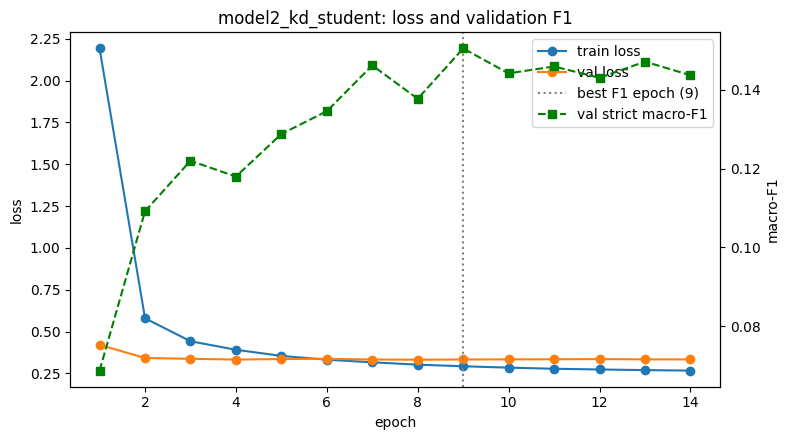

In [23]:
import matplotlib.pyplot as plt
epochs = range(1, len(history["train"]) + 1)
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(epochs, history["train"], marker="o", label="train loss")
ax1.plot(epochs, history["val"], marker="o", label="val loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss")
ax2 = ax1.twinx()
ax2.plot(epochs, history["f1"], marker="s", color="green", linestyle="--", label="val strict macro-F1")
ax2.set_ylabel("macro-F1")
best = max(range(len(history["f1"])), key=lambda i: history["f1"][i]) + 1
ax1.axvline(best, color="gray", linestyle=":", label=f"best F1 epoch ({best})")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
plt.title(f"{EXPERIMENT_NAME}: loss and validation F1")
plt.tight_layout(); plt.savefig(LOSS_PLOT_PATH, dpi=150); plt.show()

## 14. Save Final Model to Kaggle Output

In [24]:
trainable = sum(p.numel() for p in ner_model.parameters() if p.requires_grad)
teacher_params = sum(p.numel() for p in teacher_model.parameters())
run_info = {
    "experiment": EXPERIMENT_NAME, "technique": "Knowledge Distillation",
    "teacher": "PrefixLM (Model 4, full fine-tuned)", "student": "RMSSwiGLULM (Model 2)",
    "T": KD_TEMPERATURE, "alpha": KD_ALPHA,
    "epochs_run": len(history["f1"]), "best_val_f1": max(history["f1"]),
    "student_params": trainable, "teacher_params": teacher_params,
}
with open(os.path.join(OUTPUT_DIR, "run_info.json"), "w") as f:
    json.dump(run_info, f, indent=2)
print(run_info)

{'experiment': 'model2_kd_student', 'technique': 'Knowledge Distillation', 'teacher': 'PrefixLM (Model 4, full fine-tuned)', 'student': 'RMSSwiGLULM (Model 2)', 'T': 2.0, 'alpha': 0.5, 'epochs_run': 14, 'best_val_f1': 0.15054501911242352, 'student_params': 111021337, 'teacher_params': 101578777}


## For reload purpose

## Predict fold3

In [25]:
test_pred = {}
for d in test_text:
    test_pred[d] = [[int(s), int(e), lab] for s, e, lab in predict_spans(ner_model, d)]
assert set(test_pred) == set(test_text), "missing or extra document ids"
for d, spans in test_pred.items():
    n = len(test_text[d])
    for s, e, lab in spans:
        assert 0 <= s < e <= n and lab in LABELS, (d, s, e, lab)
print("docs:", len(test_pred), "| total spans:", sum(len(v) for v in test_pred.values()), "| format checks OK")

docs: 35 | total spans: 5225 | format checks OK


## 21. Save prediction.json and Create CodaBench Submission ZIP

In [26]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(test_pred, f, ensure_ascii=False)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")
print("saved:", SUBMISSION_ZIP)
with zipfile.ZipFile(SUBMISSION_ZIP) as z:
    print(z.namelist())

saved: /kaggle/working/cs781_phase2/model2_kd_student/submission.zip
['prediction.json']


In [28]:
import shutil
shutil.make_archive("/kaggle/working/phase2_backup", "zip", "/kaggle/working/cs781_phase2")
shutil.copy("/kaggle/working/a1_tokenizer.py", "/kaggle/working/cs781_phase2/a1_tokenizer.py")
print(os.path.getsize("/kaggle/working/phase2_backup.zip") / 1e6, "MB")

412.170803 MB
